# Mamba from scratch (selective SSM / S6)

Paper: Gu & Dao, *Mamba: Linear-Time Sequence Modeling with Selective State Spaces* (2023, COLM 2024).

**What is built :**
1. Discretisation of a state-space model (continuous → discrete), on tiny tensors.
2. The selective scan: a sequential version and a parallel version (fast), checked against each other.
3. A full Mamba block (projection, causal conv, selection, scan, gating) with every shape printed.
4. A Transformer baseline whose parameter count is **matched** to the Mamba model.
5. Two tasks: **selective copying** (synthetic) and a **character-level LM on TinyShakespeare**.
6. Training, comparison, and an ablation (selective vs. non-selective/LTI).


## 0. Setup

In [ ]:
import math, time, urllib.request, os
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch", torch.__version__)
torch.manual_seed(0)

device: cuda | torch 2.11.0+cu130


In [ ]:
QUICK = False

if QUICK:
    COPY = dict(L=32, K=4, V=8, d=32, layers=2, N=8, bs=32, steps=60,  lr=3e-3)
    LM   = dict(L=32, d=32, layers=2, N=8, bs=16, steps=60,  lr=3e-3)
else:
    COPY = dict(L=64, K=8, V=8, d=64,  layers=2, N=16, bs=64, steps=3000, lr=3e-3)   # selective copying
    LM   = dict(L=128,        d=128, layers=4, N=16, bs=32, steps=4000, lr=2e-3)    # char LM
print(COPY); print(LM)

{'L': 64, 'K': 8, 'V': 8, 'd': 64, 'layers': 2, 'N': 16, 'bs': 64, 'steps': 3000, 'lr': 0.003}
{'L': 128, 'd': 128, 'layers': 4, 'N': 16, 'bs': 32, 'steps': 4000, 'lr': 0.002}


## 1. Discretisation — from continuous SSM to a recurrence

A state-space model maps an input signal $x(t)$ to an output $y(t)$ through a hidden state $h(t)\in\mathbb R^N$:

$$h'(t)=A\,h(t)+B\,x(t),\qquad y(t)=C\,h(t)$$

Sequences are discrete, so we sample with step size $\Delta$. Assuming $x$ is constant between samples (zero-order hold) and solving the ODE exactly:

$$\bar A=\exp(\Delta A),\qquad \bar B=(\Delta A)^{-1}\big(\exp(\Delta A)-I\big)\,\Delta B\;\approx\;\Delta B$$

giving the recurrence

$$h_t=\bar A\,h_{t-1}+\bar B\,x_t,\qquad y_t=C\,h_t$$

Mamba uses the simple Euler form $\bar B\approx\Delta B$ because it is accurate for small $\Delta$ and cheap. In Mamba, $A$ is diagonal, so $\exp(\Delta A)$ is just an element-wise exponential , that is what makes everything cheap.

**Why $A$ is negative:** with $A<0$, $\bar A=e^{\Delta A}\in(0,1)$, so the state *decays* (stable memory). Larger $\Delta$ ⇒ $\bar A$ closer to 0 ⇒ forget faster / focus on the current input.

In [ ]:
# One channel, state size N=3. Look at how Delta changes Abar and Bbar.
A = -torch.tensor([1.0, 2.0, 3.0])          # diagonal of A (negative => stable)
B = torch.ones(3)
for delta in [0.01, 0.1, 1.0]:
    Abar = torch.exp(delta * A)                              # exact ZOH for diagonal A
    Bbar_exact = (Abar - 1) / A * B                          # (dA)^-1 (exp(dA)-1) * dB  ==  (exp(dA)-1)/A * B
    Bbar_euler = delta * B
    print(f"delta={delta:5}  Abar={Abar.numpy().round(3)}  Bbar exact={Bbar_exact.numpy().round(3)}  Bbar euler={Bbar_euler.numpy().round(3)}")

delta= 0.01  Abar=[0.99 0.98 0.97]  Bbar exact=[0.01 0.01 0.01]  Bbar euler=[0.01 0.01 0.01]
delta=  0.1  Abar=[0.905 0.819 0.741]  Bbar exact=[0.095 0.091 0.086]  Bbar euler=[0.1 0.1 0.1]
delta=  1.0  Abar=[0.368 0.135 0.05 ]  Bbar exact=[0.632 0.432 0.317]  Bbar euler=[1. 1. 1.]


Notice: for small $\Delta$ the Euler approximation matches the exact $\bar B$; for $\Delta=1$ it does not, but Mamba initialises $\Delta\in[10^{-3},10^{-1}]$ and the model learns whatever it needs.

## 2. The selective scan

Inputs (shapes, with `b`=batch, `l`=length, `d`=channels, `n`=state size):

| tensor | shape | meaning |
|---|---|---|
| `u` | (b,l,d) | input sequence |
| `delta` | (b,l,d) | step size, **depends on the input** (that is "selective") |
| `A` | (d,n) | fixed negative-real state matrix |
| `B`, `C` | (b,l,n) | input and output matrices, **depend on the input** |
| `D` | (d,) | skip connection |

Every channel `d` has its own length-`n` state, so the full state is `(b,d,n)`.

In [ ]:
def selective_scan_seq(u, delta, A, B, C, D):
    """Reference scan: a plain Python loop over time. Slow but easy to read.
    h_t = exp(delta_t * A) * h_{t-1} + delta_t * B_t * u_t ;   y_t = C_t . h_t + D * u_t"""
    b, l, d = u.shape
    dA  = torch.exp(delta.unsqueeze(-1) * A)                         # (b,l,d,n)  Abar
    dBu = delta.unsqueeze(-1) * B.unsqueeze(2) * u.unsqueeze(-1)     # (b,l,d,n)  Bbar * u
    h = u.new_zeros(b, d, A.shape[1])                                # (b,d,n)    state
    ys = []
    for t in range(l):
        h = dA[:, t] * h + dBu[:, t]                                 # state update
        ys.append((h * C[:, t].unsqueeze(1)).sum(-1))                # readout: (b,d)
    return torch.stack(ys, 1) + u * D                                # (b,l,d)

### Parallel scan (what makes training fast)
The loop above is sequential in `l`. But the update $h_t=a_t h_{t-1}+x_t$ is an *associative* operation on pairs:

$$(a_1,x_1)\circ(a_2,x_2)=(a_1a_2,\;a_2x_1+x_2)$$

so all $h_t$ can be computed with a parallel prefix scan in $\lceil\log_2 l\rceil$ rounds. Below is a Hillis–Steele scan: in round $k$ each position combines with the one $2^k$ steps before it. (The paper's CUDA kernel does this far more memory-efficiently; this is the readable version.)

In [ ]:
def selective_scan_par(u, delta, A, B, C, D):
    """Same math as selective_scan_seq, but log2(l) parallel rounds instead of l sequential steps."""
    a = torch.exp(delta.unsqueeze(-1) * A)                           # (b,l,d,n)
    x = delta.unsqueeze(-1) * B.unsqueeze(2) * u.unsqueeze(-1)       # (b,l,d,n)
    l = u.shape[1]
    off = 1
    while off < l:
        a_prev = F.pad(a[:, :-off], (0, 0, 0, 0, off, 0), value=1.0)  # shift right by `off`, pad identity (1,0)
        x_prev = F.pad(x[:, :-off], (0, 0, 0, 0, off, 0), value=0.0)
        x = a * x_prev + x                                            # (a1,x1)o(a2,x2) -> second component
        a = a * a_prev                                                # first component
        off *= 2
    y = (x * C.unsqueeze(2)).sum(-1)                                  # x now holds h_t
    return y + u * D

**Check 1:** both scans must give the same answer.

In [ ]:
torch.manual_seed(0)
b, l, d, n = 2, 37, 8, 4
u = torch.randn(b, l, d); delta = torch.rand(b, l, d) * 0.5
A = -torch.rand(d, n) * 5; B = torch.randn(b, l, n); C = torch.randn(b, l, n); D = torch.randn(d)
y1 = selective_scan_seq(u, delta, A, B, C, D); y2 = selective_scan_par(u, delta, A, B, C, D)
print("max |seq - par| =", (y1 - y2).abs().max().item())
assert torch.allclose(y1, y2, atol=1e-5)

# Also time them (on CPU, small): the parallel version has far fewer sequential steps.
u2 = torch.randn(4, 256, 16); d2 = torch.rand(4, 256, 16)*0.5; A2 = -torch.rand(16, 8)*5
B2 = torch.randn(4, 256, 8); C2 = torch.randn(4, 256, 8); D2 = torch.randn(16)
for f in (selective_scan_seq, selective_scan_par):
    t = time.time(); f(u2, d2, A2, B2, C2, D2); print(f.__name__, f"{time.time()-t:.3f}s")

max |seq - par| = 9.5367431640625e-07
selective_scan_seq 0.010s
selective_scan_par 0.006s


## 3. The Mamba block

```
x ──in_proj──▶ (x, z)            both width d_inner = expand·d_model
x ──causal depthwise conv──▶ SiLU
x ──x_proj──▶ (dt, B, C)         <- selection: parameters computed FROM the input
dt ──dt_proj──▶ softplus ──▶ Δ   (positive step size per channel & position)
y = SSM(x; Δ, A, B, C, D)        <- selective scan
y = y · SiLU(z)                  <- gating
out = out_proj(y)
```
Details worth knowing:
- `A = -exp(A_log)` is initialised as `-(1..N)` (S4D-real) so every state dimension decays at a different rate.
- `Δ` is initialised so `softplus(bias) ∈ [1e-3, 1e-1]` (log-uniform) → the model starts with long memory.
- The conv is *causal*: we pad `k-1` on the left (via `padding=k-1`) and crop to length `l`, so output `t` never sees inputs after `t`.
- `selective=False` gives the **LTI ablation**: Δ, B, C become fixed learned parameters (same for every position) → a classic time-invariant SSM.

In [ ]:
class MambaBlock(nn.Module):
    def __init__(self, d_model, d_state=16, expand=2, d_conv=4, dt_rank=None, selective=True, scan="par"):
        super().__init__()
        self.d_inner, self.d_state, self.selective = expand * d_model, d_state, selective
        self.dt_rank = dt_rank or math.ceil(d_model / 16)
        self.scan = selective_scan_par if scan == "par" else selective_scan_seq

        self.in_proj = nn.Linear(d_model, 2 * self.d_inner, bias=False)
        self.conv1d = nn.Conv1d(self.d_inner, self.d_inner, d_conv, groups=self.d_inner, padding=d_conv - 1)

        # Delta init: softplus(bias) log-uniform in [1e-3, 1e-1]  (store the inverse-softplus)
        dt = torch.exp(torch.rand(self.d_inner) * (math.log(0.1) - math.log(1e-3)) + math.log(1e-3))
        inv_softplus = dt + torch.log(-torch.expm1(-dt))
        if selective:
            self.x_proj = nn.Linear(self.d_inner, self.dt_rank + 2 * d_state, bias=False)   # x -> (dt, B, C)
            self.dt_proj = nn.Linear(self.dt_rank, self.d_inner, bias=True)
            with torch.no_grad():
                self.dt_proj.bias.copy_(inv_softplus)
                nn.init.uniform_(self.dt_proj.weight, -self.dt_rank ** -0.5, self.dt_rank ** -0.5)
        else:                                                                                # LTI ablation
            self.dt_bias = nn.Parameter(inv_softplus.clone())
            self.B_fix = nn.Parameter(torch.randn(d_state) / math.sqrt(d_state))
            self.C_fix = nn.Parameter(torch.randn(d_state) / math.sqrt(d_state))

        A = torch.arange(1, d_state + 1, dtype=torch.float32).repeat(self.d_inner, 1)       # (d_inner, N)
        self.A_log = nn.Parameter(torch.log(A))                                              # A = -exp(A_log)
        self.D = nn.Parameter(torch.ones(self.d_inner))
        self.out_proj = nn.Linear(self.d_inner, d_model, bias=False)

    def forward(self, x):                                   # x: (b, l, d_model)
        b, l, _ = x.shape
        x, z = self.in_proj(x).chunk(2, dim=-1)             # each (b, l, d_inner)
        x = self.conv1d(x.transpose(1, 2))[..., :l].transpose(1, 2)   # causal conv: crop right side
        x = F.silu(x)
        A = -torch.exp(self.A_log)                          # (d_inner, N), negative
        if self.selective:
            dt, B, C = self.x_proj(x).split([self.dt_rank, self.d_state, self.d_state], dim=-1)
            delta = F.softplus(self.dt_proj(dt))            # (b, l, d_inner), > 0
        else:
            delta = F.softplus(self.dt_bias).expand(b, l, -1)
            B = self.B_fix.expand(b, l, -1); C = self.C_fix.expand(b, l, -1)
        y = self.scan(x, delta, A, B, C, self.D)            # (b, l, d_inner)
        return self.out_proj(y * F.silu(z))                 # gate, project back to d_model

**Walkthrough:** run the block's forward pass by hand, printing each shape, and confirm it equals `block(x)`.

In [ ]:
blk = MambaBlock(d_model=16, d_state=4).eval()
x0 = torch.randn(2, 10, 16)
with torch.no_grad():
    print("input                :", tuple(x0.shape))
    xz = blk.in_proj(x0);                 print("in_proj              :", tuple(xz.shape), "(= 2*d_inner)")
    x, z = xz.chunk(2, -1);               print("  x, z               :", tuple(x.shape), tuple(z.shape))
    x = blk.conv1d(x.transpose(1, 2))[..., :10].transpose(1, 2); x = F.silu(x); print("conv+SiLU            :", tuple(x.shape))
    dt, B, C = blk.x_proj(x).split([blk.dt_rank, 4, 4], -1);     print("x_proj -> dt,B,C     :", tuple(dt.shape), tuple(B.shape), tuple(C.shape))
    delta = F.softplus(blk.dt_proj(dt));  print("delta                :", tuple(delta.shape), f"min={delta.min():.4f} (>0)")
    A = -torch.exp(blk.A_log);            print("A                    :", tuple(A.shape), f"max={A.max():.2f} (<0)")
    y = selective_scan_par(x, delta, A, B, C, blk.D); print("scan output y        :", tuple(y.shape))
    out = blk.out_proj(y * F.silu(z));    print("gated + out_proj     :", tuple(out.shape))
    print("matches block(x):", torch.allclose(out, blk(x0), atol=1e-5))

input                : (2, 10, 16)
in_proj              : (2, 10, 64) (= 2*d_inner)
  x, z               : (2, 10, 32) (2, 10, 32)
conv+SiLU            : (2, 10, 32)
x_proj -> dt,B,C     : (2, 10, 1) (2, 10, 4) (2, 10, 4)
delta                : (2, 10, 32) min=0.0011 (>0)
A                    : (32, 4) max=-1.00 (<0)
scan output y        : (2, 10, 32)
gated + out_proj     : (2, 10, 16)
matches block(x): True


**Check 2 — causality.** Change the inputs at positions ≥ 10; outputs at positions < 10 must not change. If this fails, the model could 'cheat' by looking at the future.

In [ ]:
blk = MambaBlock(16).eval()
x = torch.randn(1, 20, 16); x2 = x.clone(); x2[:, 10:] += torch.randn(1, 10, 16)
with torch.no_grad():
    same = torch.allclose(blk(x)[:, :10], blk(x2)[:, :10], atol=1e-5)
print("causal:", same); assert same

causal: True


## 4. Full language model + Transformer baseline

Both models share the same wrapper: embedding → N layers (RMSNorm → mixer → residual) → RMSNorm → tied output head. Only the *mixer* differs: `MambaBlock` vs. causal self-attention + MLP.

**Equal size:** `match_transformer` picks the Transformer's MLP width so its total parameter count matches the Mamba model.

In [ ]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-5):
        super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.w

class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads=4, d_ff=None):
        super().__init__()
        d_ff = d_ff or 4 * d_model
        self.attn = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))
        self.n1, self.n2 = RMSNorm(d_model), RMSNorm(d_model)
    def forward(self, x):
        l = x.shape[1]
        mask = torch.triu(torch.ones(l, l, dtype=torch.bool, device=x.device), 1)   # True = may NOT attend (future)
        h = self.n1(x)
        x = x + self.attn(h, h, h, attn_mask=mask, need_weights=False)[0]
        return x + self.mlp(self.n2(x))

class SeqModel(nn.Module):
    def __init__(self, vocab, d_model, n_layers, arch="mamba", max_len=512, d_state=16, selective=True, d_ff=None, n_heads=4):
        super().__init__()
        self.arch = arch
        self.emb = nn.Embedding(vocab, d_model)
        if arch == "transformer":
            self.pos = nn.Embedding(max_len, d_model)
            self.layers = nn.ModuleList([TransformerBlock(d_model, n_heads, d_ff) for _ in range(n_layers)])
        else:
            self.layers = nn.ModuleList([MambaBlock(d_model, d_state, selective=selective) for _ in range(n_layers)])
            self.norms = nn.ModuleList([RMSNorm(d_model) for _ in range(n_layers)])
        self.norm_f = RMSNorm(d_model)
        self.head = nn.Linear(d_model, vocab, bias=False); self.head.weight = self.emb.weight   # weight tying
    def forward(self, ids):
        x = self.emb(ids)
        if self.arch == "transformer":
            x = x + self.pos(torch.arange(ids.shape[1], device=ids.device))
            for layer in self.layers: x = layer(x)
        else:
            for norm, layer in zip(self.norms, self.layers): x = x + layer(norm(x))
        return self.head(self.norm_f(x))

def n_params(m): return sum(p.numel() for p in m.parameters())

def match_transformer(vocab, d_model, n_layers, target, max_len, n_heads=4):
    """Choose d_ff so the Transformer has ~`target` parameters (params are linear in d_ff)."""
    p1 = n_params(SeqModel(vocab, d_model, n_layers, "transformer", max_len, d_ff=d_model, n_heads=n_heads))
    p2 = n_params(SeqModel(vocab, d_model, n_layers, "transformer", max_len, d_ff=2 * d_model, n_heads=n_heads))
    slope = (p2 - p1) / d_model                       # params per unit of d_ff
    d_ff = max(8, round(d_model + (target - p1) / slope))
    return SeqModel(vocab, d_model, n_layers, "transformer", max_len, d_ff=d_ff, n_heads=n_heads), d_ff

## 5. Task 1 - Selective copying (synthetic)

The input has `K` data tokens at **random positions** among noise tokens (`0`), followed by `K` recall markers. The model must output the data tokens, in order, at the marker positions.

```
input : 0 0 5 0 0 3 0 7 0 0 0 2 0 0 | R R R R
target:                               5 3 7 2
```
A time-invariant model applies the same dynamics at every position, so it cannot know *which* positions to remember. A selective model can: it writes to the state only when the input is a data token. This is the paper's motivating task.

In [ ]:
def selective_copy_batch(bs, L, K, V, gen=None):
    ids = torch.zeros(bs, L + K, dtype=torch.long)                 # 0 = noise
    tgt = torch.full((bs, L + K), -100, dtype=torch.long)          # -100 = ignored by the loss
    pos = torch.rand(bs, L, generator=gen).argsort(1)[:, :K].sort(1).values      # K random positions, sorted
    vals = torch.randint(1, V + 1, (bs, K), generator=gen)         # data tokens 1..V
    ids.scatter_(1, pos, vals)
    ids[:, L:] = V + 1                                             # recall markers
    tgt[:, L:] = vals
    return ids.to(device), tgt.to(device)

x, y = selective_copy_batch(3, COPY["L"], COPY["K"], COPY["V"])
for i in range(3):
    print("input :", x[i].tolist()); print("target:", y[i][y[i] != -100].tolist(), "\n")

input : [0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 8, 0, 0, 0, 0, 2, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 7, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 8, 3, 0, 0, 0, 9, 9, 9, 9, 9, 9, 9, 9]
target: [5, 8, 2, 1, 7, 3, 8, 3] 

input : [4, 0, 0, 0, 0, 8, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 7, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 4, 0, 0, 0, 9, 9, 9, 9, 9, 9, 9, 9]
target: [4, 8, 7, 7, 5, 2, 5, 4] 

input : [0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 7, 0, 0, 6, 0, 0, 0, 0, 0, 0, 8, 0, 4, 0, 0, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 9, 9, 9, 9, 9, 9, 9, 9]
target: [2, 3, 7, 6, 8, 4, 7, 7] 



## 6. Training utilities
One generic loop for both tasks. Loss is cross-entropy (on the last `K` positions only for copying). We use AdamW, a one-cycle LR schedule and gradient clipping.

In [ ]:
def train(model, get_batch, evaluate, steps, lr, name, log_every=None):
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.1)
    log_every = log_every or max(steps // 15, 1)
    hist, t0 = [], time.time()
    print(f"[{name}] {n_params(model)/1e3:.1f}K params")
    for step in range(1, steps + 1):
        model.train()
        x, y = get_batch()
        loss = F.cross_entropy(model(x).reshape(-1, model.head.out_features), y.reshape(-1), ignore_index=-100)
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        if step % log_every == 0 or step == steps:
            r = {"step": step, "loss": loss.item(), "time": time.time() - t0, **evaluate(model)}
            hist.append(r); print(f"  step {step:5d} | " + " | ".join(f"{k} {v:.4f}" for k, v in r.items() if k != "step"))
    return hist

@torch.no_grad()
def eval_copy(model):
    model.eval(); g = torch.Generator().manual_seed(999)
    x, y = selective_copy_batch(512, COPY["L"], COPY["K"], COPY["V"], g)
    pred = model(x).argmax(-1); m = y != -100
    return {"tok_acc": (pred[m] == y[m]).float().mean().item(),
            "seq_acc": ((pred == y) | ~m).all(1).float().mean().item()}   # all K outputs right

## 7. Train on selective copying: Mamba vs. LTI ablation vs. Transformer
All three have the same `d_model` and number of layers; the Transformer's MLP width is set so its parameter count matches Mamba.

In [ ]:
VOCAB_COPY = COPY["V"] + 2                                   # noise + V data tokens + marker
copy_models = {"Mamba": SeqModel(VOCAB_COPY, COPY["d"], COPY["layers"], "mamba", d_state=COPY["N"], selective=True),
               "Mamba-LTI (no selection)": SeqModel(VOCAB_COPY, COPY["d"], COPY["layers"], "mamba", d_state=COPY["N"], selective=False)}
tf, d_ff = match_transformer(VOCAB_COPY, COPY["d"], COPY["layers"], n_params(copy_models["Mamba"]), COPY["L"] + COPY["K"])
copy_models["Transformer (param-matched)"] = tf
for k, m in copy_models.items(): print(f"{k:30s} {n_params(m):>8,d} params")
print("transformer d_ff =", d_ff)

Mamba                            66,112 params
Mamba-LTI (no selection)         55,936 params
Transformer (param-matched)      66,066 params
transformer d_ff = 105


In [25]:
copy_hist = {}
g_train = torch.Generator().manual_seed(1)
for name, model in copy_models.items():
    copy_hist[name] = train(model, lambda: selective_copy_batch(COPY["bs"], COPY["L"], COPY["K"], COPY["V"], g_train),
                            eval_copy, COPY["steps"], COPY["lr"], name)

[Mamba] 66.1K params
  step   200 | loss 0.4306 | time 21.5204 | tok_acc 0.8752 | seq_acc 0.2656
  step   400 | loss 0.2896 | time 43.3216 | tok_acc 0.9021 | seq_acc 0.3652
  step   600 | loss 0.2071 | time 65.1189 | tok_acc 0.9370 | seq_acc 0.5645
  step   800 | loss 0.0907 | time 86.9048 | tok_acc 0.9727 | seq_acc 0.7891
  step  1000 | loss 0.0141 | time 108.6961 | tok_acc 0.9827 | seq_acc 0.8672
  step  1200 | loss 0.1131 | time 130.5294 | tok_acc 0.9749 | seq_acc 0.8027
  step  1400 | loss 0.0019 | time 152.3604 | tok_acc 0.9988 | seq_acc 0.9941
  step  1600 | loss 0.0005 | time 174.1870 | tok_acc 0.9988 | seq_acc 0.9902
  step  1800 | loss 0.0014 | time 196.0147 | tok_acc 1.0000 | seq_acc 1.0000
  step  2000 | loss 0.0000 | time 217.8411 | tok_acc 1.0000 | seq_acc 1.0000
  step  2200 | loss 0.0000 | time 239.6714 | tok_acc 1.0000 | seq_acc 1.0000
  step  2400 | loss 0.0000 | time 261.4951 | tok_acc 1.0000 | seq_acc 1.0000
  step  2600 | loss 0.0000 | time 283.3170 | tok_acc 1.0000

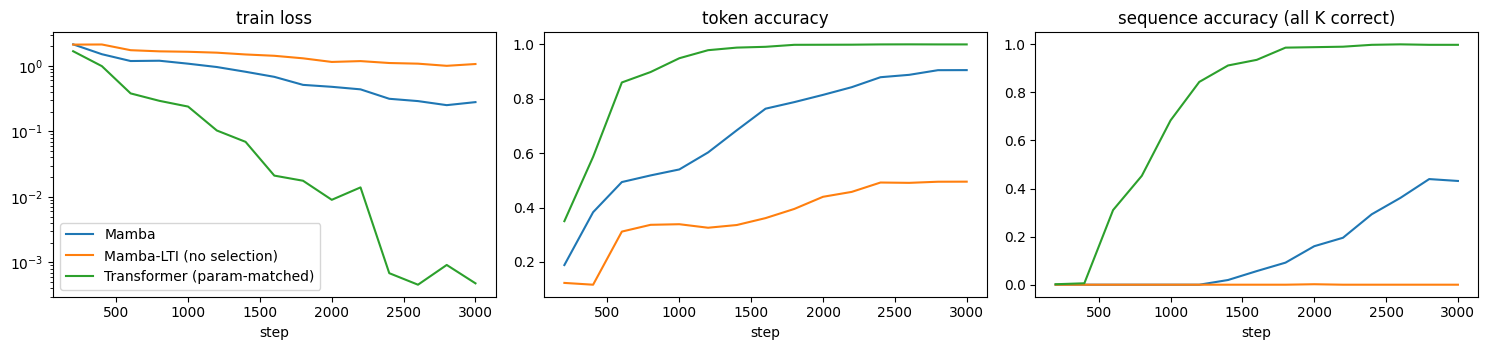

model                             params  tok_acc  seq_acc
Mamba                             66,112    0.905    0.432
Mamba-LTI (no selection)          55,936    0.495    0.000
Transformer (param-matched)       66,066    1.000    0.998


In [24]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for name, h in copy_hist.items():
    s = [r["step"] for r in h]
    ax[0].plot(s, [r["loss"] for r in h], label=name); ax[1].plot(s, [r["tok_acc"] for r in h], label=name); ax[2].plot(s, [r["seq_acc"] for r in h], label=name)
for a, t in zip(ax, ["train loss", "token accuracy", "sequence accuracy (all K correct)"]): a.set_title(t); a.set_xlabel("step")
ax[0].set_yscale("log"); ax[0].legend(); plt.tight_layout(); plt.show()
print(f"{'model':30s} {'params':>9s} {'tok_acc':>8s} {'seq_acc':>8s}")
for name, h in copy_hist.items(): print(f"{name:30s} {n_params(copy_models[name]):>9,d} {h[-1]['tok_acc']:>8.3f} {h[-1]['seq_acc']:>8.3f}")

**What to look for:** the selective Mamba should learn the task; the LTI variant should stay near chance (it cannot choose which tokens to keep) — that is the core claim of the paper. The Transformer can solve it because attention looks up content directly. Results at this small scale come from a single seed: re-run with different `torch.manual_seed` values before drawing conclusions.

## 8. Task 2 - Character-level language model on TinyShakespeare
The metric is **bits per character** (validation cross-entropy divided by ln 2; lower is better).

In [ ]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
if not os.path.exists("tinyshakespeare.txt"): urllib.request.urlretrieve(URL, "tinyshakespeare.txt")
text = open("tinyshakespeare.txt", encoding="utf-8").read()
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}
data = torch.tensor([stoi[c] for c in text]); n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]
VOCAB_LM = len(chars)
print(f"{len(text):,} chars, vocab {VOCAB_LM}; train {len(train_data):,} / val {len(val_data):,}")
print(text[:200])

def lm_batch(src, bs, L, gen=None):
    ix = torch.randint(0, len(src) - L - 1, (bs,), generator=gen)
    x = torch.stack([src[i:i + L] for i in ix]); y = torch.stack([src[i + 1:i + L + 1] for i in ix])
    return x.to(device), y.to(device)

@torch.no_grad()
def eval_lm(model):
    model.eval(); g = torch.Generator().manual_seed(999); tot = 0
    for _ in range(20):
        x, y = lm_batch(val_data, LM["bs"], LM["L"], g)
        tot += F.cross_entropy(model(x).reshape(-1, VOCAB_LM), y.reshape(-1)).item()
    nll = tot / 20
    return {"val_bpc": nll / math.log(2), "val_ppl": math.exp(nll)}

In [ ]:
lm_models = {"Mamba": SeqModel(VOCAB_LM, LM["d"], LM["layers"], "mamba", d_state=LM["N"], selective=True),
             "Mamba-LTI (no selection)": SeqModel(VOCAB_LM, LM["d"], LM["layers"], "mamba", d_state=LM["N"], selective=False)}
tf, d_ff = match_transformer(VOCAB_LM, LM["d"], LM["layers"], n_params(lm_models["Mamba"]), LM["L"])
lm_models["Transformer (param-matched)"] = tf
for k, m in lm_models.items(): print(f"{k:30s} {n_params(m):>9,d} params")
print("transformer d_ff =", d_ff)

In [21]:
lm_hist = {}
g_lm = torch.Generator().manual_seed(2)
for name, model in lm_models.items():
    lm_hist[name] = train(model, lambda: lm_batch(train_data, LM["bs"], LM["L"], g_lm), eval_lm, LM["steps"], LM["lr"], name)

[Mamba] 474.9K params
  step   266 | loss 2.1395 | time 102.8035 | val_bpc 3.1443 | val_ppl 8.8415
  step   532 | loss 1.6870 | time 208.1992 | val_bpc 2.7448 | val_ppl 6.7028
  step   798 | loss 1.5685 | time 313.6031 | val_bpc 2.5661 | val_ppl 5.9220
  step  1064 | loss 1.4973 | time 419.0193 | val_bpc 2.4738 | val_ppl 5.5549
  step  1330 | loss 1.4103 | time 524.4270 | val_bpc 2.4336 | val_ppl 5.4024
  step  1596 | loss 1.4034 | time 629.8412 | val_bpc 2.3933 | val_ppl 5.2534
  step  1862 | loss 1.4526 | time 735.2533 | val_bpc 2.3486 | val_ppl 5.0933
  step  2128 | loss 1.3584 | time 840.6545 | val_bpc 2.3550 | val_ppl 5.1160
  step  2394 | loss 1.2934 | time 946.0692 | val_bpc 2.3586 | val_ppl 5.1286
  step  2660 | loss 1.2740 | time 1051.4838 | val_bpc 2.3527 | val_ppl 5.1079
  step  2926 | loss 1.2795 | time 1156.9062 | val_bpc 2.3427 | val_ppl 5.0725
  step  3192 | loss 1.2496 | time 1262.3347 | val_bpc 2.3459 | val_ppl 5.0837
  step  3458 | loss 1.2200 | time 1367.7479 | val_b

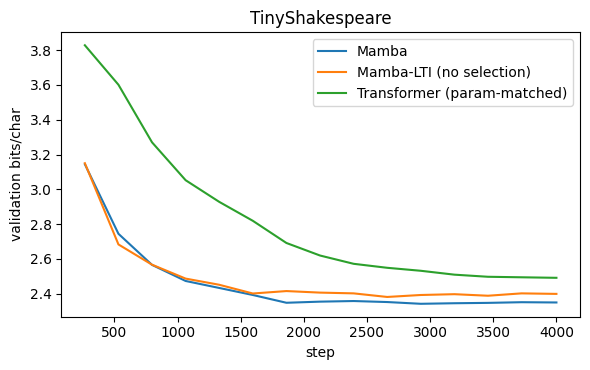

model                             params  val_bpc  val_ppl  time(s)
Mamba                            474,880    2.350     5.10     1585
Mamba-LTI (no selection)         425,856    2.400     5.28     1576
Transformer (param-matched)      474,572    2.492     5.63       64


In [22]:
plt.figure(figsize=(6, 3.8))
for name, h in lm_hist.items(): plt.plot([r["step"] for r in h], [r["val_bpc"] for r in h], label=name)
plt.xlabel("step"); plt.ylabel("validation bits/char"); plt.legend(); plt.title("TinyShakespeare"); plt.tight_layout(); plt.show()
print(f"{'model':30s} {'params':>9s} {'val_bpc':>8s} {'val_ppl':>8s} {'time(s)':>8s}")
for name, h in lm_hist.items(): print(f"{name:30s} {n_params(lm_models[name]):>9,d} {h[-1]['val_bpc']:>8.3f} {h[-1]['val_ppl']:>8.2f} {h[-1]['time']:>8.0f}")

In [23]:
@torch.no_grad()
def generate(model, prompt="ROMEO:", n=300, temperature=0.8):
    model.eval()
    ids = torch.tensor([[stoi[c] for c in prompt]], device=device)
    for _ in range(n):
        logits = model(ids[:, -LM["L"]:])[:, -1] / temperature
        ids = torch.cat([ids, torch.multinomial(F.softmax(logits, -1), 1)], 1)
    return "".join(itos[i] for i in ids[0].tolist())
print(generate(lm_models["Mamba"]))

ROMEO:
I am I need me to in God's head,
To have I like tongue for my hour in the king,
And is the prisonment that the sheathe content
To mercy a pleasant few the great death.
Lay the particullant benefit of something most
wrong the people, make like a own first before the
partness of thy friendly reign.




## 10. Things to try (to understand what matters)
1. **Seeds:** re-run sections 7 and 8 with different seeds. Is the LM gap between Mamba and LTI real or noise?
2. **State size:** change `N` in `COPY` to 1, 4, 16. How little state is enough?
3. **Selectivity pieces:** in `MambaBlock`, make only Δ selective (fix B, C) — the paper finds Δ matters most.
4. **Length:** increase `COPY["L"]` and watch which model degrades.
5. **Sequential vs parallel:** build the model with `scan="seq"` and compare speed and outputs.
6. **Inspect Δ:** after training, plot `delta` for a selective-copy input. Is Δ large on data tokens and small on noise tokens? That is selection happening.

**Honest caveats:** this uses a pure-PyTorch scan (no fused CUDA kernel), small models and short training, so absolute numbers are not comparable to the paper — only the qualitative comparison is meaningful.